In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

import matplotlib
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import colors
from matplotlib import rcParams
from matplotlib import cm
import seaborn as sns

import anndata as ad
import gseapy as gp
import scipy as sci
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.multitest import fdrcorrection
from mudata import MuData
import muon as mu
from cellphonedb.utils import search_utils

2026-07-06 11:09:45.093695: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-06 11:09:45.142258: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-06 11:09:45.905258: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=120, facecolor='white',figsize=(4,4))
sc.logging.print_header()
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['font.family']='Helvetica'
plt.rcParams['pdf.fonttype'] = 42
%config InlineBackend.figure_format='retina'

scanpy==1.9.8 anndata==0.9.2 umap==0.5.5 numpy==1.23.5 scipy==1.10.1 pandas==2.0.3 scikit-learn==1.3.2 statsmodels==0.14.0 igraph==0.11.5 louvain==0.8.2 pynndescent==0.5.2


# Load Data

In [4]:
mdata=mu.read("/data1/liyuzhe/data_share/brain_tumor/adata_MB_multimodal_aucell_results.h5mu")
mdata_tme=mu.read("/data1/liyuzhe/data_share/brain_tumor/adata_TME_rna_atac_celltype.h5mu")
mdata=mdata[~mdata.obs.celltype.isin(['Oligodendrocyte'])].copy()

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/mudata/_core/mudata.py:491: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  warnings.warn(
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/mudata/_core/mudata.py:491: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  warnings.warn(


In [5]:
metadata=pd.read_table('data/metadata.tsv')

In [6]:
mdata=mdata[metadata[metadata.cell_type.isin(['Group3', 'Group4','SHH'])].barcode_sample]
mdata_tme=mdata_tme[metadata[~metadata.cell_type.isin(['Group3', 'Group4','SHH'])].barcode_sample]

In [7]:
adata=mdata['rna']
chromvar=mdata['chromVAR']
adata_reg=mdata['regulon']

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


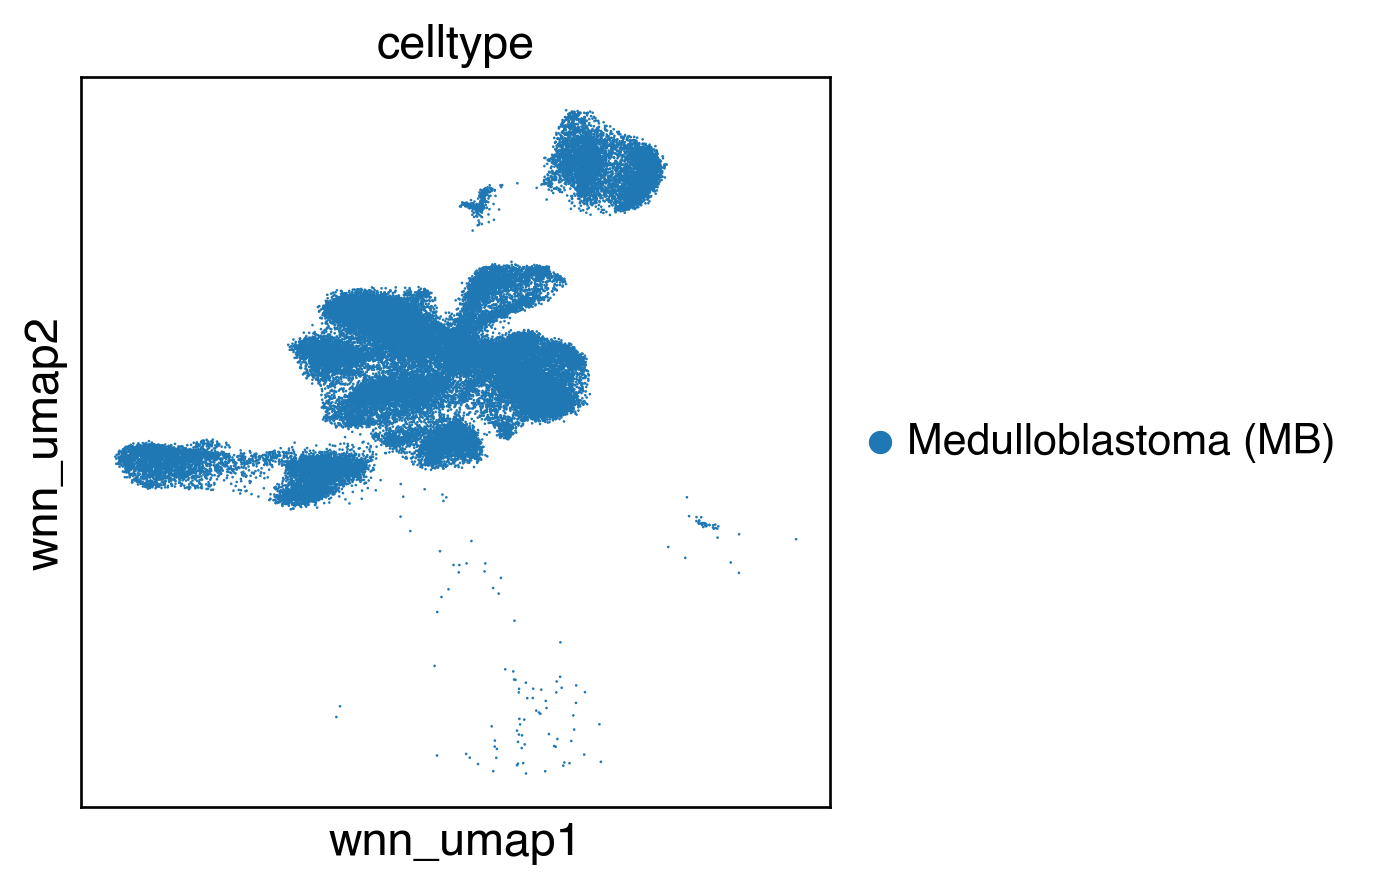

In [8]:
sc.pl.embedding(adata_reg,basis='wnn_umap',color='celltype')

In [9]:
figR=pd.read_csv('/home/liyuzhe/Notebook/Pediatric_brain_tumor_2026/Fig1-2/3_FigR/MB/results/figR_d.csv',index_col=0)
# rtf=pd.read_csv('/home/liyuzhe/Notebook/Pediatric_brain_tumor_pub2/CCI/MB/data/RTF_human.csv',index_col=0)
rtf=pd.read_csv('/home/liyuzhe/Notebook/Pediatric_brain_tumor_2026/Fig5/5_CCI/data/RTF_human.csv',index_col=0)
# 2) output from cellphonedb
means = pd.read_csv("results/method2/statistical_analysis_means_03_19_2026_11:00:36.txt", sep="\t")
pvalues = pd.read_csv("results/method2/statistical_analysis_pvalues_03_19_2026_11:00:36.txt", sep="\t")
deconvoluted = pd.read_csv("results/method2/statistical_analysis_deconvoluted_03_19_2026_11:00:36.txt", sep="\t")
significant_means = pd.read_csv("results/method2/statistical_analysis_significant_means_03_19_2026_11:00:36.txt", sep="\t")

In [10]:
ref=pd.read_csv('/data1/liyuzhe/Ref/cpdb/v5.0.0/interaction_input.csv')

In [11]:
figR=figR[figR.Score>1]
tfs=[i.split('_')[0] for i in adata_reg.var.index]

In [12]:
cts=['Group3', 'Group4', 'Lymphocyte', 'Macrophage_01_CD44',
       'Macrophage_02_FLT1', 'Macrophage_03_FYN', 'Microglia_01_P2RY12',
       'Microglia_02_DNAJB1', 'Microglia_03_IGF2R', 'Microglia_04_ITGAX',
       'Microglia_05_KLF2', 'Microglia_06_IL1B', 'Microglia_07_MKI67', 'SHH']

In [13]:
search_results = search_utils.search_analysis_results(
    query_cell_types_1 = cts,  # List of cells 1, will be paired to cells 2 (list or 'All').
    query_cell_types_2 = cts,     # List of cells 2, will be paired to cells 1 (list or 'All').
    # query_genes = ['VEGFA'],                                       # filter interactions based on the genes participating (list).
    # query_interactions = ['VEGFA_ITGAV'],                            # filter intereactions based on their name (list).
    significant_means = significant_means,                          # significant_means file generated by CellPhoneDB.
    deconvoluted = deconvoluted,                                    # devonvoluted file generated by CellPhoneDB.
    separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
    long_format = True                                              # converts the output into a wide table, removing non-significant interactions
)

In [14]:
# search_results.columns

In [15]:
# np.unique(search_results.interacting_cells)

In [16]:
# search_results=search_results[search_results.interacting_cells.isin(['Lymphocyte|MB','Macrophage|MB', 'Microglia|MB'])]

In [17]:
search_results.head()

,interacting_pair,partner_a,partner_b,gene_a,gene_b,interacting_cells,significant_mean
1,CDH7_CDH7,simple:Q9ULB5,simple:Q9ULB5,CDH7,CDH7,Group3|Group3,0.110
5,Glutamate_byGLS_and_SLC1A7_Glutamate_Kainate_2...,complex:Glutamate_byGLS_and_SLC1A7,complex:Glutamate_Kainate_2_4_complex,NaN,NaN,Group3|Group3,0.277
6,Glutamate_byGLS_and_SLC1A7_GRIA1,complex:Glutamate_byGLS_and_SLC1A7,simple:P42261,NaN,GRIA1,Group3|Group3,0.210
12,Glutamate_byGLS_and_SLC1A7_GRM4,complex:Glutamate_byGLS_and_SLC1A7,simple:Q14833,NaN,GRM4,Group3|Group3,0.182
14,EFNA5_EPHA7,simple:P52803,simple:Q15375,EFNA5,EPHA7,Group3|Group3,0.239


# LRTF

In [18]:
l_ref=[]
for i in ref.index:
    if ref.loc[i,'directionality']=='Ligand-Receptor':
        l_ref.append(ref.loc[i,'interactors'].split('-')[0])
l_ref=list(set(l_ref))

In [19]:
len(l_ref)

660

In [20]:
cdb=search_results[['interacting_pair', 'gene_a', 'gene_b','interacting_cells', 'significant_mean']].copy()
cell_a=[]
cell_b=[]
for i in cdb.index:
    cell_a.append(cdb.loc[i,'interacting_cells'].split('|')[0])
    cell_b.append(cdb.loc[i,'interacting_cells'].split('|')[1])
ligand=[]
receptor=[]
for i in cdb.index:
    gene_a=cdb.loc[i,'gene_a']        
    gene_b=cdb.loc[i,'gene_b']
    interacting_pair=cdb.loc[i,'interacting_pair']
    if pd.isnull(cdb.loc[i,'gene_b']) or pd.isnull(cdb.loc[i,'gene_a']):
        ligand.append('None')
        receptor.append('None')
    else:
        tmp=pvalues[pvalues.interacting_pair==interacting_pair]
        if tmp.receptor_b.values[0] and ~tmp.receptor_a.values[0]:
            receptor.append(gene_b)
            ligand.append(gene_a)
        elif tmp.receptor_a.values[0] and ~tmp.receptor_b.values[0]:
            receptor.append(gene_a)
            ligand.append(gene_b)
        else:
            if tmp.gene_a.values[0] in l_ref:
                receptor.append(gene_b)
                ligand.append(gene_a)
            elif tmp.gene_b.values[0] in l_ref:
                receptor.append(gene_a)
                ligand.append(gene_b)
            else:
                receptor.append('both')
                ligand.append('both')

cdb['ligand']=ligand
cdb['receptor']=receptor
cdb['cell_a']=cell_a
cdb['cell_b']=cell_b

In [21]:
cdb.shape

(6325, 9)

In [22]:
cdb.loc[cdb.interacting_pair=='CRTAM_CADM1','ligand']='CADM1'
cdb.loc[cdb.interacting_pair=='CRTAM_CADM1','receptor']='CRTAM'

In [23]:
idx=[]
for i in cdb.index:
    if cdb.loc[i,'ligand']==cdb.loc[i,'gene_a'] and cdb.loc[i,'cell_a'] not in ['Group3', 'Group4','SHH']:
        idx.append(i)
    elif cdb.loc[i,'ligand']==cdb.loc[i,'gene_b'] and cdb.loc[i,'cell_b'] not in ['Group3', 'Group4','SHH']:
        idx.append(i)
    elif cdb.loc[i,'ligand']=='both':
        idx.append(i)
len(idx)  
cdb=cdb.loc[idx]

In [24]:
cts1=['Group3', 'Group4', 'SHH']
cts2=['Lymphocyte', 'Macrophage_01_CD44',
       'Macrophage_02_FLT1', 'Macrophage_03_FYN', 'Microglia_01_P2RY12',
       'Microglia_02_DNAJB1', 'Microglia_03_IGF2R', 'Microglia_04_ITGAX',
       'Microglia_05_KLF2', 'Microglia_06_IL1B', 'Microglia_07_MKI67',]

ic=[]
for i in cts1:
    for j in cts2:
        ic.append(i+'|'+j)
        ic.append(j+'|'+i)

In [25]:
cdb=cdb[cdb.interacting_cells.isin(ic)]

In [26]:
len(np.unique(cdb.interacting_pair))

49

In [27]:
cdb.shape

(467, 9)

In [28]:
cdb.to_csv('results/LR_results.csv')

In [29]:
for g in ['Group3', 'Group4', 'SHH']:
    TFT=figR[figR.Motif.isin(tfs)]
    TFT['from']=TFT.Motif.copy()
    TFT['to']=TFT.DORC.copy()
    TFT['source']='FigR'
    TFT['path']=['*'.join([TFT.loc[i,'from'],TFT.loc[i,'to']]) for i in TFT.index]

    ligands = []
    receptors = []
    for i in cdb.index:
        if cdb.loc[i,'ligand']!='None':
            if cdb.loc[i,'ligand']=='both':
                if cdb.loc[i,'cell_b'] in ['Group3', 'Group4', 'SHH']:
                    ligands.append(cdb.loc[i,'gene_a'])
                    receptors.append(cdb.loc[i,'gene_b'])
                elif cdb.loc[i,'cell_a'] in ['Group3', 'Group4', 'SHH']:
                    ligands.append(cdb.loc[i,'gene_b'])
                    receptors.append(cdb.loc[i,'gene_a'])
            else:
                ligands.append(cdb.loc[i,'ligand'])
                receptors.append(cdb.loc[i,'receptor'])
    receptors=list(set(receptors)) 
    ligands=list(set(ligands)) 
    RTF = rtf[(rtf['to'].isin(tfs))&(rtf['from'].isin(receptors))]

    RTF['from.Role'] = "Receptor"
    RTF['to.Role'] = "TF"

    TFT['from.Role'] = "TF"
    TFT['to.Role'] = "Target"

    df=RTF[['from','to','path']].copy()
    df.columns=['Receptor','TF','path']
    df.index=df.path.copy()
    
    exp_rec_df_all=pd.DataFrame(adata.raw[:,receptors].X.A,index=mdata.obs.index,columns=receptors)
    regulon_df_all=pd.DataFrame(adata_reg[:,[i+'_+' for i in tfs]].X,index=mdata.obs.index,columns=tfs)
    idx=metadata[metadata.cell_type==g].barcode_sample
    exp_rec_df=exp_rec_df_all.loc[idx]
    regulon_df=regulon_df_all.loc[idx]
    
    r_df = pd.DataFrame(np.ones((exp_rec_df.shape[1], regulon_df.shape[1])), columns=regulon_df.columns, index=exp_rec_df.columns)
    rp_df = pd.DataFrame(np.ones((exp_rec_df.shape[1], regulon_df.shape[1])), columns=regulon_df.columns, index=exp_rec_df.columns)
    for i in exp_rec_df.columns:
        for j in regulon_df.columns:
            tmp=pd.concat([exp_rec_df[[i]],regulon_df[[j]]],axis=1)
            tmp.columns=['rec','reg']
            r,p=sci.stats.pearsonr(tmp['rec'],tmp['reg'])
            r_df.loc[i, j] = r
            rp_df.loc[i, j] = p
    r_df=r_df.loc[np.unique(df.Receptor),np.unique(df.TF)]
    rp_df=rp_df.loc[np.unique(df.Receptor),np.unique(df.TF)]
    for i in df.index:
        df.loc[i,'r']=r_df.loc[df.loc[i,'Receptor'],df.loc[i,'TF']]
        df.loc[i,'p_corr']=rp_df.loc[df.loc[i,'Receptor'],df.loc[i,'TF']]
        df.loc[i,'regulon_score']=regulon_df[[df.loc[i,'TF']]].mean().values[0]
    df['p_corr_adj']=fdrcorrection(df.p_corr)[1]
    df.to_csv('results/sig_pathway_all_{}.csv'.format(g))
    df=df[(df.r > 0.05)&(df.p_corr_adj< 0.05)].copy()
    RTF=RTF[RTF.path.isin(df.index)]
    TFT=TFT[TFT['from'].isin(RTF['to'])]
    RTF.to_csv('results/RTF_{}.csv'.format(g))
    TFT.to_csv('results/TTF_{}.csv'.format(g))
    df.to_csv('results/sig_pathway_{}.csv'.format(g))

/tmp/ipykernel_410505/398620528.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TFT['from']=TFT.Motif.copy()
/tmp/ipykernel_410505/398620528.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TFT['to']=TFT.DORC.copy()
/tmp/ipykernel_410505/398620528.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing